# WattRota — Firma Üretim Verisi

İki öğütme hattı, ortak paketleme ve ayrı dökme/torbalı yükleme noktaları bulunan kurgusal bir çimento firmasının veri seti hazırlanmıştır. Üç ürün ve 72 saatlik döneme yayılan dökme/torbalı siparişler birlikte ele alınır.

Üretim kapasitesi, güç, stok, hazırlık süresi ve gider değerleri senaryo varsayımlarıdır; ölçülmüş fabrika kayıtları değildir. Saatlik PTF, EPİAŞ 2025 CSV dosyasından alınmıştır. Üretim ve sevkiyat planı fiyatlara bakılmadan oluşturulmuştur.

## 1. Veri oluşturma

Veri tanımları `src/firma_verisi.py` içinde pandas tabloları olarak tutulur. Sabit senaryo aynı girdilerle yeniden üretilebilir. Bu dosya bir optimizasyon modeli çalıştırmaz.


In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

proje_dizini = Path("..").resolve()
sys.path.insert(0, str(proje_dizini / "src"))
from firma_verisi import (
    firma_verisini_olustur, firma_planini_dogrula,
    hata_kontrolleri, veri_paketini_kaydet,
)

veriler = firma_verisini_olustur(proje_dizini)
display(veriler["kaynaklar"])
display(veriler["kaynak_urun"])


,kaynak_id,kaynak_adi,kaynak_turu
0,H01,Öğütme hattı 1,ogutme
1,H02,Öğütme hattı 2,ogutme
2,P01,Ortak paketleme hattı,paketleme
3,Y01,Dökme yükleme,dokme_yukleme
4,Y02,Torbalı yükleme,torbali_yukleme


,kaynak_id,urun_id,kapasite_ton_saat,calisma_gucu_kw
0,H01,UR01,60,1800
1,H01,UR02,70,1800
2,H01,UR03,50,1900
3,H02,UR01,70,2100
4,H02,UR02,80,2200
5,P01,UR01,80,100
6,P01,UR02,100,120
7,P01,UR03,60,90
8,Y01,UR01,180,60
9,Y01,UR02,180,60


## 2. Üretim rotaları ve uygun makineler

Bir rota, ürünün hangi işlemlerden hangi sırayla geçtiğini gösterir. Dökme siparişte öğütme ve dökme yükleme; torbalı siparişte öğütme, paketleme ve torbalı yükleme bulunur. İşlemler arasında ürünlere ayrılmış stoklar vardır.

`rotalar.csv` işlem sırasını, `rota_kaynaklari.csv` her adımda kullanılabilecek kaynakları gösterir. UR01 ve UR02 iki öğütme hattında, UR03 yalnız H01'de üretilebilir. Bu uygunluk matrisi senaryo tercihidir.


In [2]:
rota_gorunumu = veriler["rotalar"].merge(
    veriler["rota_kaynaklari"], on=["rota_id", "adim_no"], validate="one_to_many"
)
display(rota_gorunumu[["rota_id", "adim_no", "islem_turu", "kaynak_id", "girdi_stok_turu", "cikti_stok_turu"]])


,rota_id,adim_no,islem_turu,kaynak_id,girdi_stok_turu,cikti_stok_turu
0,R_UR01_dokme,1,ogutme,H01,hammadde,dokme
1,R_UR01_dokme,1,ogutme,H02,hammadde,dokme
2,R_UR01_dokme,2,dokme_yukleme,Y01,dokme,teslim
3,R_UR01_torbali,1,ogutme,H01,hammadde,dokme
4,R_UR01_torbali,1,ogutme,H02,hammadde,dokme
5,R_UR01_torbali,2,paketleme,P01,dokme,torbali
6,R_UR01_torbali,3,torbali_yukleme,Y02,torbali,teslim
7,R_UR02_dokme,1,ogutme,H01,hammadde,dokme
8,R_UR02_dokme,1,ogutme,H02,hammadde,dokme
9,R_UR02_dokme,2,dokme_yukleme,Y01,dokme,teslim


## 3. Müşteri siparişleri ve iş emirleri

**Sipariş** müşteriye verilecek ürün, miktar ve teslim zamanı bilgisidir. **İş emri**, üretim veya paketleme görevidir. Öğütme aynı ürünün dökme ve torbalı taleplerini birlikte karşılayabilir; bu nedenle her satış siparişi için ayrı bir öğütme bloğu açılmamıştır.

İş emirleri gün–ürün–işlem bazında oluşturulmuştur. Uygun makineler ve çalışma blokları arasında bölünebilir. `is_emri_siparis_baglantisi.csv`, her emrin hangi siparişleri ne miktarda desteklediğini gösterir. Öğütme ve paketleme tahsisleri ayrı aşamalardır; ikisi toplanarak fiziksel ürün miktarı bulunmaz.

Paketleme, yalnızca önceki saatten mevcut dökme stokla yapılır. Bu nedenle bir öğütme iş emrinin bütünü bitmeden stoktan paketleme yapılabilir. Öncelik koşulu, tüm emrin bitişine değil malzemenin stokta hazır olmasına bağlıdır. Başlangıç stokları ve dönem sonu hedefleri bu hesapta korunur.


In [3]:
display(veriler["siparisler"])
display(veriler["is_emirleri"])
display(veriler["is_emri_siparis_baglantisi"].head(12))

print("Sipariş sayısı:", len(veriler["siparisler"]))
print("İş emri sayısı:", len(veriler["is_emirleri"]))
print("Toplam müşteri talebi (ton):", veriler["siparisler"]["miktar_ton"].sum())


Sipariş sayısı: 18
İş emri sayısı: 18
Toplam müşteri talebi (ton): 6720


,siparis_id,urun_id,miktar_ton,teslim_turu,rota_id,gelis_zamani,en_erken_yukleme,teslim_zamani
0,SP1_UR01_dokme,UR01,720,dokme,R_UR01_dokme,2025-10-06,2025-10-06 08:00:00,2025-10-06 18:00:00
1,SP1_UR01_torbali,UR01,320,torbali,R_UR01_torbali,2025-10-06,2025-10-06 08:00:00,2025-10-06 12:00:00
2,SP1_UR02_dokme,UR02,400,dokme,R_UR02_dokme,2025-10-06,2025-10-06 08:00:00,2025-10-06 12:00:00
3,SP1_UR02_torbali,UR02,400,torbali,R_UR02_torbali,2025-10-06,2025-10-06 08:00:00,2025-10-06 15:00:00
4,SP1_UR03_dokme,UR03,160,dokme,R_UR03_dokme,2025-10-06,2025-10-06 08:00:00,2025-10-06 17:00:00
5,SP1_UR03_torbali,UR03,240,torbali,R_UR03_torbali,2025-10-06,2025-10-06 08:00:00,2025-10-06 18:00:00
6,SP2_UR01_dokme,UR01,720,dokme,R_UR01_dokme,2025-10-06,2025-10-07 08:00:00,2025-10-07 18:00:00
7,SP2_UR01_torbali,UR01,320,torbali,R_UR01_torbali,2025-10-06,2025-10-07 08:00:00,2025-10-07 12:00:00
8,SP2_UR02_dokme,UR02,400,dokme,R_UR02_dokme,2025-10-06,2025-10-07 08:00:00,2025-10-07 12:00:00
9,SP2_UR02_torbali,UR02,400,torbali,R_UR02_torbali,2025-10-06,2025-10-07 08:00:00,2025-10-07 15:00:00


,is_emri_id,urun_id,islem_turu,miktar_ton,serbest_birakma,tamamlanma_siniri,bolunebilir
0,IE1_UR01_ogutme,UR01,ogutme,1040,2025-10-06,2025-10-07 00:00:00,True
1,IE1_UR01_paketleme,UR01,paketleme,320,2025-10-06,2025-10-06 14:00:00,True
2,IE1_UR02_ogutme,UR02,ogutme,800,2025-10-06,2025-10-07 00:00:00,True
3,IE1_UR02_paketleme,UR02,paketleme,400,2025-10-06,2025-10-06 14:00:00,True
4,IE1_UR03_ogutme,UR03,ogutme,400,2025-10-06,2025-10-07 00:00:00,True
5,IE1_UR03_paketleme,UR03,paketleme,240,2025-10-06,2025-10-06 14:00:00,True
6,IE2_UR01_ogutme,UR01,ogutme,1040,2025-10-06,2025-10-08 00:00:00,True
7,IE2_UR01_paketleme,UR01,paketleme,320,2025-10-06,2025-10-07 14:00:00,True
8,IE2_UR02_ogutme,UR02,ogutme,800,2025-10-06,2025-10-08 00:00:00,True
9,IE2_UR02_paketleme,UR02,paketleme,400,2025-10-06,2025-10-07 14:00:00,True


,is_emri_id,siparis_id,tahsis_ton
0,IE1_UR01_ogutme,SP1_UR01_dokme,720
1,IE1_UR01_ogutme,SP1_UR01_torbali,320
2,IE1_UR01_paketleme,SP1_UR01_torbali,320
3,IE1_UR02_ogutme,SP1_UR02_dokme,400
4,IE1_UR02_ogutme,SP1_UR02_torbali,400
5,IE1_UR02_paketleme,SP1_UR02_torbali,400
6,IE1_UR03_ogutme,SP1_UR03_dokme,160
7,IE1_UR03_ogutme,SP1_UR03_torbali,240
8,IE1_UR03_paketleme,SP1_UR03_torbali,240
9,IE2_UR01_ogutme,SP2_UR01_dokme,720


## 4. Stok ve kaynak kuralları

Dökme ve torbalı stoklar ayrı izlenir. Öğütme çıktısı dökme siloya, paketleme çıktısı torbalı stoğa girer. Dökme stoktan paketlemeye ve dökme yüklemeye çıkan miktarlar birlikte düşülür. Aynı ton iki kez kullanılamaz.

Her kaynak aynı saatte tek faaliyet yürütür. Ürün değişimleri, minimum üretim/duruş süreleri, bakım ve ortak güç sınırı uygulanır. Hazırlık sırasında üretim olmaz; başlangıç ürün ayarları ve kapalı süreler kayıtlarda tutulur.


In [4]:
display(veriler["stok_alanlari"])
display(veriler["depo_kurallari"])
display(veriler["isletme_kurallari"])
display(veriler["urun_gecisleri"])
display(veriler["bakimlar"])


,stok_id,urun_id,stok_turu,minimum_ton,kapasite_ton,baslangic_ton,son_hedef_ton
0,D01,UR01,dokme,60,1200,240,240
1,D02,UR02,dokme,80,1600,900,900
2,D03,UR03,dokme,50,800,180,180
3,T01,UR01,torbali,0,600,120,120
4,T02,UR02,torbali,0,700,100,100
5,T03,UR03,torbali,0,400,80,80


,depo_id,toplam_kapasite_ton
0,TORBALI_DEPO,1100


,kaynak_id,minimum_uretim_saat,minimum_durus_saat,baslangicta_aktif,baslangic_durum_suresi_saat,baslangic_urun_ayari,baslatma_enerjisi_kwh,baslatma_elektrik_disi_gider_tl
0,H01,4,2,False,4,UR01,100,200
1,H02,4,2,False,4,UR02,120,250
2,P01,2,1,False,4,UR01,30,40


,kaynak_id,onceki_urun,sonraki_urun,hazirlik_saat,hazirlik_gucu_kw,elektrik_disi_gider_tl
0,H01,UR01,UR02,1,300,75
1,H01,UR01,UR03,2,300,75
2,H01,UR02,UR01,1,300,75
3,H01,UR02,UR03,2,300,75
4,H01,UR03,UR01,2,300,75
5,H01,UR03,UR02,2,300,75
6,H02,UR01,UR02,1,300,75
7,H02,UR02,UR01,1,300,75
8,P01,UR01,UR02,1,35,20
9,P01,UR01,UR03,1,35,20


,kaynak_id,baslangic,bitis
0,H01,2025-10-07 20:00:00,2025-10-07 22:00:00
1,H02,2025-10-06 21:00:00,2025-10-06 23:00:00
2,P01,2025-10-08 20:00:00,2025-10-08 21:00:00
3,Y01,2025-10-07 12:00:00,2025-10-07 13:00:00


## 5. Referans planın uygunluğu

Verinin üretilebilirliğini kontrol etmek için fiyatı dikkate almayan bir üretim, paketleme ve sevkiyat planı kurulmuştur. Kontrol fonksiyonu bu planı saat saat yeniden hesaplar. Dönem başı stoktan çıkışlar düşülür, dönem sonunda üretim ve paketleme çıktıları eklenir.

Kontroller kaynak uygunluğunu, iş emri miktarını ve zamanını, rota bağlantılarını, hazırlığı, çalışma/duruş sürelerini, stok sınırlarını, teslimatı, bakımı ve ortak güç sınırını kapsar. Hammadde yeterli, besleme kuru ve reçete sabit kabul edilmiştir; laboratuvar kalite doğrulaması, fırın ve su/gaz dengesi bu kapsamda değildir.


In [5]:
stok_hareketleri, faaliyetler, saatlik_sonuc = firma_planini_dogrula(veriler)

talep_ozeti = veriler["siparisler"].groupby(["urun_id", "teslim_turu"])["miktar_ton"].sum().unstack()
display(talep_ozeti)

stok_sonu = stok_hareketleri.groupby(["urun_id", "stok_turu"])["son_stok_ton"].last()
display(stok_sonu)
print("En yüksek saatlik ortalama güç (kW):", saatlik_sonuc["toplam_enerji_kwh"].max())
print("Ortak güç sınırı (kW):", veriler["tesis_takvimi"]["guc_siniri_kw"].min())
print("Bütün referans plan kontrolleri geçti.")


En yüksek saatlik ortalama güç (kW): 4650.0
Ortak güç sınırı (kW): 4700
Bütün referans plan kontrolleri geçti.


teslim_turu,dokme,torbali
urun_id,,
UR01,2160,960
UR02,1200,1200
UR03,480,720


urun_id  stok_turu
UR01     dokme        240.0
         torbali      120.0
UR02     dokme        900.0
         torbali      100.0
UR03     dokme        180.0
         torbali       80.0
Name: son_stok_ton, dtype: float64

## 6. Kaynak kullanımı ve stok görünümü

Kullanım oranları, bu senaryonun çalışma yükünü gösterir; sektörün tipik kapasite kullanım oranı olarak yorumlanmaz. Faaliyet oranı üretim ve hazırlığı birlikte, net üretim oranı yalnız üretim saatlerini içerir. Yükleme noktalarında aktif saatler, kendi kullanılabilir takvimleri üzerinden değerlendirilir.


,kaynak_id,uygun_saat,net_islem_saat,aktif_saat,net_kullanim_pct,aktif_kullanim_pct
0,H01,70,48,54,68.57,77.14
1,H02,70,54,57,77.14,81.43
2,P01,71,36,44,50.70,61.97
3,Y01,29,24,24,82.76,82.76
4,Y02,30,27,27,90.00,90.00


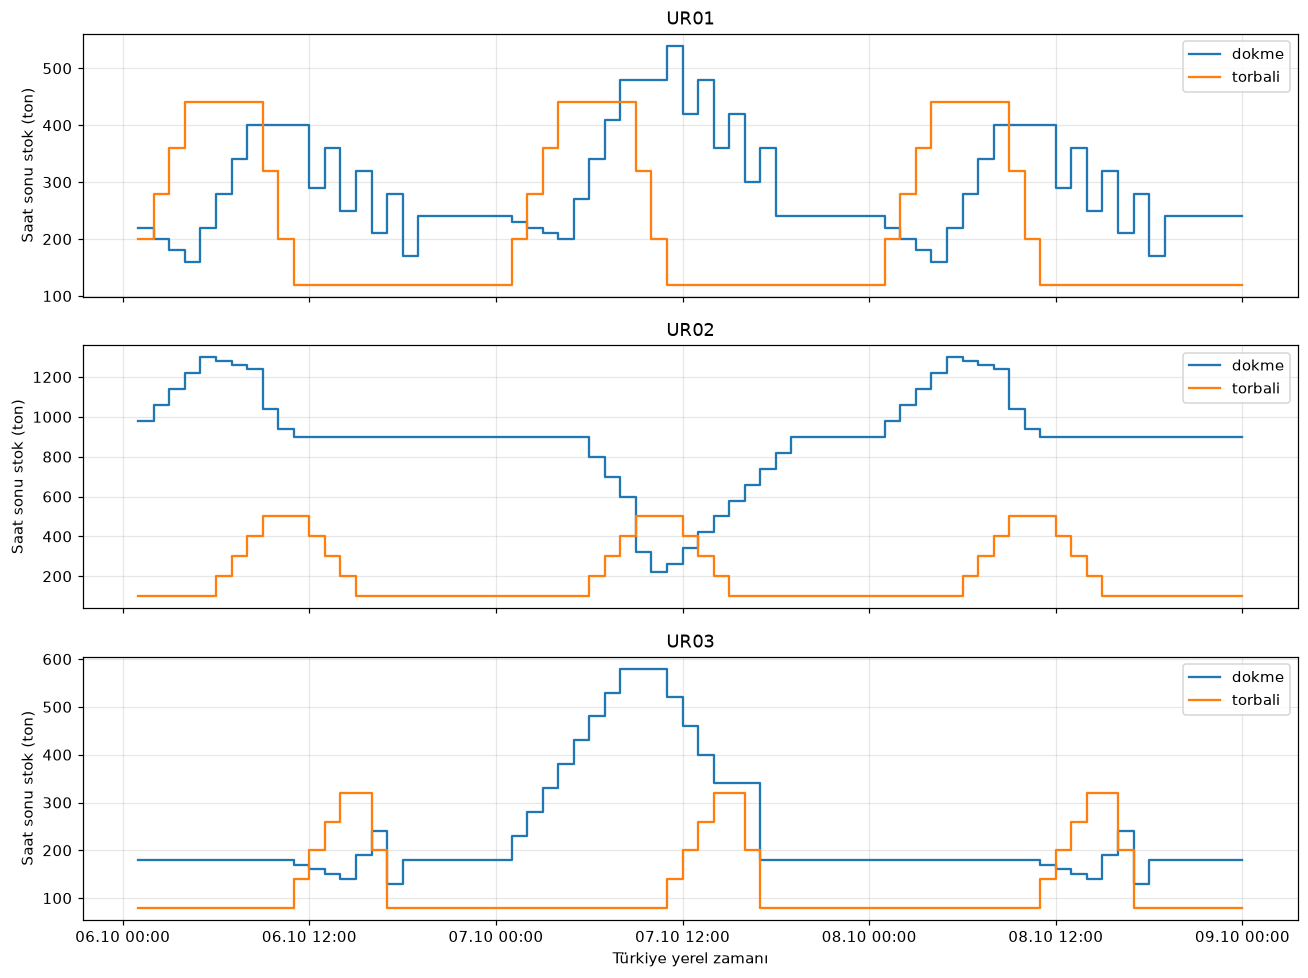

In [6]:
kullanim = []
for r in veriler["kaynaklar"]["kaynak_id"]:
    uygun_saat = int(veriler["kaynak_takvimi"].loc[veriler["kaynak_takvimi"]["kaynak_id"] == r, "kullanilabilir"].sum())
    if r in ["H01", "H02", "P01"]:
        f = faaliyetler[faaliyetler["kaynak_id"] == r]
        net_saat = int(f["durum"].eq("uretim").sum())
        aktif_saat = int(f["durum"].ne("kapali").sum())
    else:
        net_saat = int(veriler["referans_yuklemeler"].loc[veriler["referans_yuklemeler"]["kaynak_id"] == r, "tarih_saat"].nunique())
        aktif_saat = net_saat
    kullanim.append([r, uygun_saat, net_saat, aktif_saat, 100 * net_saat / uygun_saat, 100 * aktif_saat / uygun_saat])
kullanim = pd.DataFrame(kullanim, columns=["kaynak_id", "uygun_saat", "net_islem_saat", "aktif_saat", "net_kullanim_pct", "aktif_kullanim_pct"])
display(kullanim.round(2))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, p in zip(axes, ["UR01", "UR02", "UR03"]):
    for tur in ["dokme", "torbali"]:
        hareket = stok_hareketleri[(stok_hareketleri["urun_id"] == p) & (stok_hareketleri["stok_turu"] == tur)]
        ax.step(hareket["tarih_saat"] + pd.Timedelta(hours=1), hareket["son_stok_ton"], where="post", label=tur)
    ax.set_title(p)
    ax.set_ylabel("Saat sonu stok (ton)")
    ax.legend()
    ax.grid(alpha=0.3)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
axes[-1].set_xlabel("Türkiye yerel zamanı")
plt.tight_layout()
plt.show()


## 7. Hatalı veri ve plan örnekleri

Kaynak uygunluğu, eksik hazırlık, malzeme yetersizliği, silo/depo kapasitesi, bakım, güç sınırı, yanlış yükleme noktası, geç/eksik teslimat, iş emri tahsisi, rota ve son stok ihlalleri oluşturularak reddedildikleri sınanmıştır.


In [7]:
test_sonuclari = hata_kontrolleri(veriler)
display(test_sonuclari)
print("Reddedilen hatalı örnek sayısı:", len(test_sonuclari))


Reddedilen hatalı örnek sayısı: 13


,deneme,sonuc,yakalanan_ihlal
0,Uygun olmayan makinede ürün,Reddedildi,H02: ürün uygunluğu/ayar ihlali.
1,Ürün değişimi hazırlığı atlama,Reddedildi,H01: eksik/fazla hazırlık.
2,Paketleme için dökme stok yok,Reddedildi,"('UR01', 'dokme'), 2025-10-06 00:00:00: dönem ..."
3,Dökme silo taşması,Reddedildi,"('UR01', 'dokme'), 2025-10-06 05:00:00: stok k..."
4,Ortak torbalı depo kapasitesi,Reddedildi,2025-10-06 01:00:00: ortak torbalı depo doldu.
5,Bakımda üretim,Reddedildi,H01: bakım/uygunluk ihlali.
6,Ortak elektrik güç sınırı,Reddedildi,2025-10-06 00:00:00: ortak güç sınırı aşıldı.
7,Dökme siparişi torbalı noktadan yükleme,Reddedildi,SP1_UR01_dokme: yanlış yükleme kaynağı.
8,Geç teslimat,Reddedildi,SP1_UR01_dokme: teslim aralığı ihlali.
9,Eksik sevkiyat,Reddedildi,SP1_UR01_dokme: eksik/fazla teslimat.


## 8. Veri dosyalarının kaydı

Girdi dosyaları `data/synthetic/firma_01`, referans plan ve kontrol çıktıları `data/results/firma_01_veri_kontrolu` klasörlerinde saklanır. `veri_sozlugu.csv` alanları; `parametre_dayanaklari.csv` sayısal varsayımları açıklar. Kod yeniden çalıştırıldığında aynı senaryo yeniden üretilir. Ham EPİAŞ dosyaları değiştirilmez.


In [8]:
girdi_klasoru, sonuc_klasoru, veri_sozlugu = veri_paketini_kaydet(
    veriler, stok_hareketleri, faaliyetler, saatlik_sonuc, test_sonuclari, proje_dizini
)
print("Girdiler:", girdi_klasoru)
print("Referans ve kontroller:", sonuc_klasoru)
display(veri_sozlugu.head(12))


Girdiler: C:\Users\Victus\Documents\ChatGPT\WattRota\data\synthetic\firma_01
Referans ve kontroller: C:\Users\Victus\Documents\ChatGPT\WattRota\data\results\firma_01_veri_kontrolu


,dosya,alan,veri_turu,birim,aciklama,dayanak
0,urunler.csv,urun_id,str,—,Ürün kimliği,Sentetik firma senaryosu
1,urunler.csv,urun_adi,str,—,Senaryo ürün adı,Sentetik firma senaryosu
2,kaynaklar.csv,kaynak_id,str,—,Makine/hat/yükleme kimliği,Sentetik firma senaryosu
3,kaynaklar.csv,kaynak_adi,str,—,Kaynak açıklaması,Sentetik firma senaryosu
4,kaynaklar.csv,kaynak_turu,str,—,"ogutme, paketleme, dokme_yukleme veya torbali_...",Sentetik firma senaryosu
5,kaynak_urun.csv,kaynak_id,str,—,Makine/hat/yükleme kimliği,Sentetik firma senaryosu
6,kaynak_urun.csv,urun_id,str,—,Ürün kimliği,Sentetik firma senaryosu
7,kaynak_urun.csv,kapasite_ton_saat,int64,ton/saat,Uygun ürün için saatlik çıktı veya yükleme kap...,Sentetik firma senaryosu
8,kaynak_urun.csv,calisma_gucu_kw,int64,kW,Aktif saatte kaynak ve kapsanan yardımcıların ...,Sentetik firma senaryosu
9,isletme_kurallari.csv,kaynak_id,str,—,Makine/hat/yükleme kimliği,Sentetik firma senaryosu


## 9. Sonuç ve veri niteliği

18 sipariş için 6.720 ton ürün talebi tanımlanmıştır. Aynı miktar öğütülür; bunun 2.880 tonu ayrıca paketlenir. Paketleme miktarı öğütme miktarına eklenerek toplam ürün sayılmaz. Gün–ürün–işlem bazında 18 iş emri ve altı ürün/teslim rotası bulunur.

Referans planın stok dengeleri, teslimatları, iş emirleri ve kaynak koşulları doğrulanmıştır. Dönem sonu stokları başlangıç seviyelerine dönmektedir. Bu sonuç veri setinin tanımlanan varsayımlarla yapılabilir olduğunu gösterir; en düşük maliyetli plan bulunduğu veya gerçek tesiste aynı sonuçların elde edileceği anlamına gelmez.

Kaynaklar süreç akışının dayanağıdır; senaryodaki sayısal parametreler gerçek işletme ölçümü olarak kullanılmaz:

- [ECRA Teknoloji Raporu 2022](https://api.ecra-online.org/fileadmin/files/tp/ECRA_Technology_Papers_2022.pdf): Öğütme esnekliği ve stok/işletme bağlantıları.
- [HAVER & BOECKER — Cement](https://www.haverboecker.com/en/industries/cement/): Silo, paketleme ve sevkiyat süreçleri.
- [BEUMER — Cement](https://www.beumergroup.com/industry/cement/): Torbalı ürün elleçleme ve yükleme akışı.
- [EPİAŞ Şeffaflık Platformu](https://seffaflik.epias.com.tr/): Gerçekleşmiş saatlik PTF.

Torbalı yükleme kapasitesi ton/saat cinsinden toplulaştırılmıştır; palet ve kamyon seferleri ayrı kararlar değildir. Başlangıç stokları nedeniyle bir siparişin bütün öğütmesinin tamamlanmasını beklemek yerine kullanılabilir malzeme takip edilir. Gelecekteki fiyatlar üretim verisi tasarımında kullanılmamıştır.
